# IEEE Paper Figures 10–14 — YOLOv11 vs YOLOv26 (Brain Tumor Segmentation)

This notebook rebuilds **Figures 10, 11, 12, 13 and 14** from the **original
YOLO validation output images**, combining them into the same multi-panel
layout used in the paper:

- Each panel keeps its **bold sub-caption** underneath it — e.g. *"(a). Box
  Detection Performance for YOLOv11"* — matching the paper's alignment and
  style exactly.
- **No overall figure title** is drawn on the image itself (add the "Figure N.
  <caption>" text in Word below the image, as the rest of the paper does).

| Figure | Source files (per model) | Layout |
|---|---|---|
| 10 | `BoxP_curve.png`, `MaskP_curve.png` | 2×2, (a)–(d) |
| 11 | `BoxR_curve.png`, `MaskR_curve.png` | 2×2, (a)–(d) |
| 12 | `BoxF1_curve.png`, `MaskF1_curve.png` | 2×2, (a)–(d) |
| 13 | `BoxPR_curve.png`, `MaskPR_curve.png` | 2×2, (a)–(d) |
| 14 | `confusion_matrix_normalized.png` | 1×2, (a)–(b) |

Panel order for Figures 10–13 (matches the paper):
- **(a)** Box — YOLOv11
- **(b)** Mask — YOLOv11
- **(c)** Box — YOLOv26
- **(d)** Mask — YOLOv26

Panel order for Figure 14:
- **(a)** YOLOv11 confusion matrix (normalized)
- **(b)** YOLOv26 confusion matrix (normalized)

> **Before running:** edit the three paths in the *Configuration* cell below
> (`YOLO11_DIR`, `YOLO26_DIR`, `OUTPUT_DIR`), then Run All.


### **FIGURE 10.** Loss Performance for the YOLOv11 and YOLOv26 for Brain Tumor Segmentation and Classification.

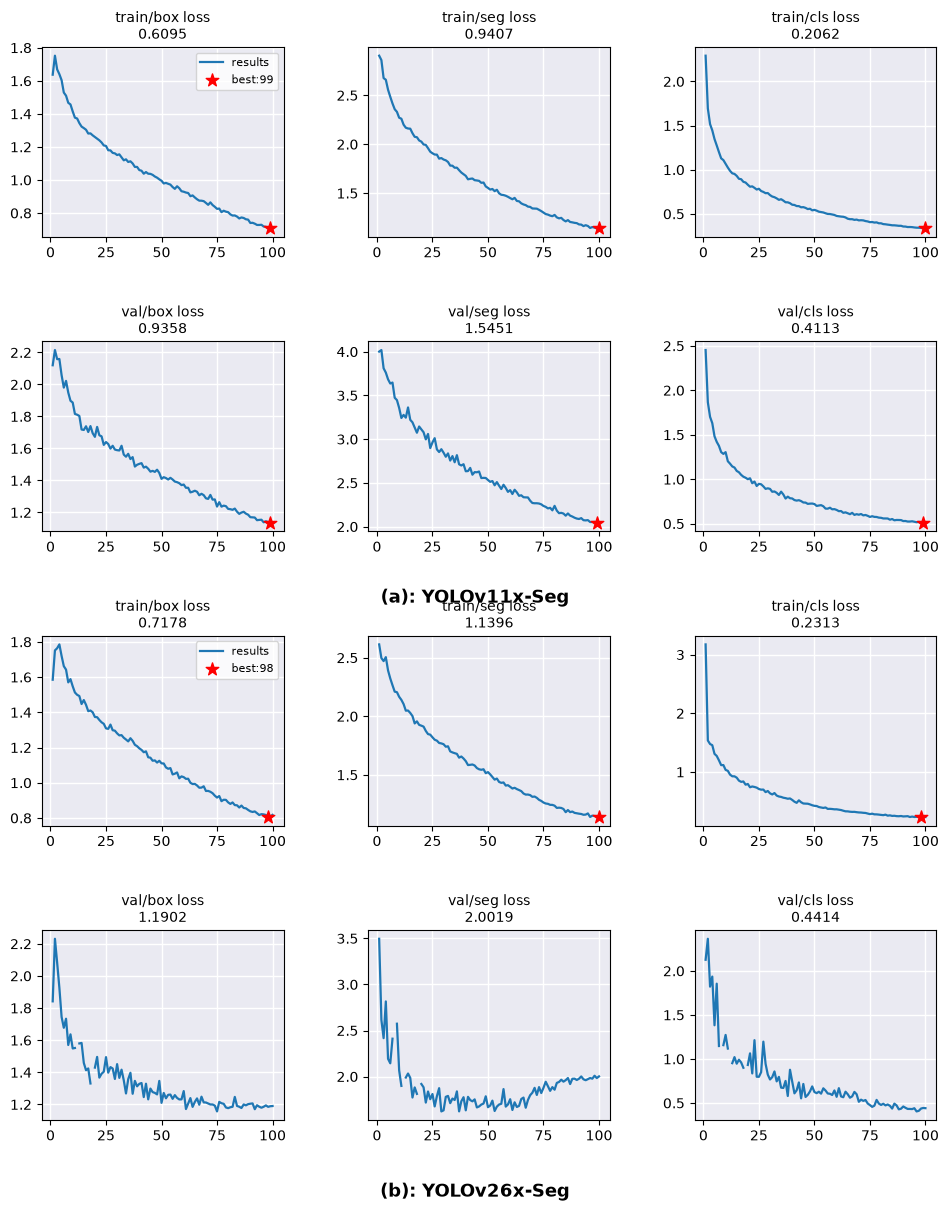

Saved: FIGURE_9_Loss_Performance_YOLOv11_vs_YOLOv26.svg


In [2]:
"""
Reproduces a 4x3 loss-curve figure (train/val x box/seg/cls) comparing
YOLOv11x-Seg (top block) vs YOLOv26x-Seg (bottom block), styled to match
the reference Ultralytics-style results plot.

Requirements:
    pip install pandas matplotlib numpy

Usage:
    Just run this file. Edit CSV_11 / CSV_26 paths below if needed.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. CONFIG
# ----------------------------------------------------------------------
CSV_11 = r"C:\Users\miraj\Documents\Research Paper's\Brain Tumor Segmentation and Classification\notebooks\yolo11_results.csv"
CSV_26 = r"C:\Users\miraj\Documents\Research Paper's\Brain Tumor Segmentation and Classification\notebooks\yolo26_results.csv"

OUT_PATH = "FIGURE_9_Loss_Performance_YOLOv11_vs_YOLOv26.svg"

# Metrics to plot, in column order (box, seg, cls only -- dfl excluded)
METRICS = ["box_loss", "seg_loss", "cls_loss"]
SPLITS = ["train", "val"]  # row order within each model block

# Fixed values to display in each subplot title (from Table 3).
# The star marker is still placed at the actual best/minimum epoch found
# in the CSV -- only the printed number is overridden to match the table.
TABLE_VALUES = {
    "YOLOv11": {
        ("train", "box_loss"): 0.6095,
        ("train", "seg_loss"): 0.9407,
        ("train", "cls_loss"): 0.2062,
        ("val", "box_loss"): 0.9358,
        ("val", "seg_loss"): 1.5451,
        ("val", "cls_loss"): 0.4113,
    },
    "YOLOv26": {
        ("train", "box_loss"): 0.7178,
        ("train", "seg_loss"): 1.1396,
        ("train", "cls_loss"): 0.2313,
        ("val", "box_loss"): 1.1902,
        ("val", "seg_loss"): 2.0019,
        ("val", "cls_loss"): 0.4414,
    },
}

LINE_COLOR = "#1f77b4"     # matplotlib default blue (matches reference)
LINE_WIDTH = 1.6           # same weight for every sub-line
STAR_COLOR = "red"
STAR_SIZE = 90
FACE_COLOR = "#EAEAF2"     # seaborn "darkgrid" lavender-grey background
GRID_COLOR = "white"

# ----------------------------------------------------------------------
# 2. HELPERS
# ----------------------------------------------------------------------
def load_results(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]  # ultralytics csvs often have leading spaces
    return df


def get_epoch_axis(df):
    if "epoch" in df.columns:
        return df["epoch"].to_numpy()
    return np.arange(1, len(df) + 1)


def find_col(df, split, metric):
    """Match a column like 'train/box_loss' robustly to naming variants."""
    candidates = [
        f"{split}/{metric}",
        f"{split}/{metric.replace('_loss', '')}_loss",
        f"{split}_{metric}",
    ]
    for c in candidates:
        if c in df.columns:
            return c
    # fallback: fuzzy contains-match
    key = metric.split("_")[0]  # box / seg / cls
    for c in df.columns:
        if split in c and key in c and "loss" in c:
            return c
    raise KeyError(f"Could not find column for split='{split}', metric='{metric}' "
                    f"in columns: {list(df.columns)}")


def plot_block(fig, axes_block, df, model_label, show_legend_row0=True):
    """
    axes_block: 2 x 3 array of Axes (row0 = train, row1 = val)
    """
    x = get_epoch_axis(df)

    for r, split in enumerate(SPLITS):
        for c, metric in enumerate(METRICS):
            ax = axes_block[r, c]
            col = find_col(df, split, metric)
            y = df[col].to_numpy()

            line, = ax.plot(x, y, color=LINE_COLOR, linewidth=LINE_WIDTH,
                             label="results")

            # Star marks the actual best (minimum-loss) epoch from the CSV
            best_idx = int(np.argmin(y))
            best_epoch = int(x[best_idx])
            best_val = y[best_idx]
            ax.scatter(x[best_idx], best_val, marker="*",
                       s=STAR_SIZE, color=STAR_COLOR, zorder=5,
                       label=f"best:{best_epoch}")

            # Title value comes from Table 3, not the CSV
            display_val = TABLE_VALUES[model_label][(split, metric)]
            title_metric = f"{split}/{metric.replace('_', ' ')}"
            ax.set_title(f"{title_metric}\n{display_val:.4f}", fontsize=10)

            ax.set_facecolor(FACE_COLOR)
            ax.grid(True, color=GRID_COLOR, linewidth=1.0)
            ax.set_axisbelow(True)
            for spine in ax.spines.values():
                spine.set_visible(True)

            # legend only on the very first subplot of each model's block
            if show_legend_row0 and r == 0 and c == 0:
                ax.legend(loc="upper right", fontsize=8, frameon=True)


# ----------------------------------------------------------------------
# 3. LOAD DATA
# ----------------------------------------------------------------------
df11 = load_results(CSV_11)
df26 = load_results(CSV_26)

# ----------------------------------------------------------------------
# 4. FIGURE: 4 rows (train11, val11, train26, val26) x 3 cols (box, seg, cls)
#    All subplots share identical size/aspect -> equal "length and weight"
# ----------------------------------------------------------------------
n_rows, n_cols = 4, 3
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3.2 * n_cols, 3.0 * n_rows),
    squeeze=False,
)

block_11 = axes[0:2, :]  # rows 0-1 -> YOLOv11 (train, val)
block_26 = axes[2:4, :]  # rows 2-3 -> YOLOv26 (train, val)

plot_block(fig, block_11, df11, "YOLOv11", show_legend_row0=True)
plot_block(fig, block_26, df26, "YOLOv26", show_legend_row0=True)

# Block captions, centered under each 2-row block (like the reference image)
fig.text(0.5, 0.505, "(a): YOLOv11x-Seg", ha="center", va="top",
          fontsize=13, fontweight="bold")
fig.text(0.5, 0.01, "(b): YOLOv26x-Seg", ha="center", va="top",
          fontsize=13, fontweight="bold")

plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.subplots_adjust(hspace=0.55, wspace=0.35)

fig.savefig(OUT_PATH, format="svg", bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_PATH}")

## 1. Configuration — EDIT THESE PATHS

In [1]:

from pathlib import Path

# ============================================================
# EDIT THESE THREE PATHS FOR YOUR MACHINE
# ============================================================

# Folder that directly contains BoxP_curve.png, MaskP_curve.png,
# confusion_matrix_normalized.png, etc. for YOLOv11
YOLO11_DIR = r"C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv11x_Seg_Complete_Results\YOLOv11x-Seg\validation\val_run"

# Same, for YOLOv26
YOLO26_DIR = r"C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv26x_Seg_Complete_Results_best\YOLOv26x-Seg\validation\val_run"

# Where the combined, publication-ready PNGs will be saved
OUTPUT_DIR = r"C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures"

# Output resolution. 300 is fine for print; 400-600 gives extra-crisp PNGs.
DPI = 400

# Model display names used in the sub-captions (change only if you rename models)
MODEL_A_NAME = "YOLOv11"
MODEL_B_NAME = "YOLOv26"

# ============================================================
YOLO11_DIR = Path(YOLO11_DIR)
YOLO26_DIR = Path(YOLO26_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("YOLOv11 source folder:", YOLO11_DIR)
print("YOLOv26 source folder:", YOLO26_DIR)
print("Output folder:        ", OUTPUT_DIR)


YOLOv11 source folder: C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv11x_Seg_Complete_Results\YOLOv11x-Seg\validation\val_run
YOLOv26 source folder: C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv26x_Seg_Complete_Results_best\YOLOv26x-Seg\validation\val_run
Output folder:         C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures


## 2. Imports

In [2]:

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

%matplotlib inline


## 3. Sanity check — confirm the expected files exist

Run this before building the figures. It checks every filename this notebook
needs against both `YOLO11_DIR` and `YOLO26_DIR` and reports anything missing,
so a typo in the path fails fast with a clear message instead of a cryptic
matplotlib error later on.


In [3]:

REQUIRED_FILES = [
    "BoxP_curve.png", "MaskP_curve.png",
    "BoxR_curve.png", "MaskR_curve.png",
    "BoxF1_curve.png", "MaskF1_curve.png",
    "BoxPR_curve.png", "MaskPR_curve.png",
    "confusion_matrix_normalized.png",
]

def check_folder(folder, label):
    missing = []
    print(f"--- {label}: {folder} ---")
    if not folder.exists():
        print(f"  FOLDER DOES NOT EXIST: {folder}")
        return REQUIRED_FILES
    for fname in REQUIRED_FILES:
        ok = (folder / fname).exists()
        print(f"  [{'OK' if ok else 'MISSING'}] {fname}")
        if not ok:
            missing.append(fname)
    return missing

missing_11 = check_folder(YOLO11_DIR, "YOLOv11")
missing_26 = check_folder(YOLO26_DIR, "YOLOv26")

if missing_11 or missing_26:
    print("\n\u26a0\ufe0f  Some files are missing \u2014 fix the paths/filenames above before continuing.")
else:
    print("\n\u2705 All required files found. You can proceed to build the figures.")


--- YOLOv11: C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv11x_Seg_Complete_Results\YOLOv11x-Seg\validation\val_run ---
  [OK] BoxP_curve.png
  [OK] MaskP_curve.png
  [OK] BoxR_curve.png
  [OK] MaskR_curve.png
  [OK] BoxF1_curve.png
  [OK] MaskF1_curve.png
  [OK] BoxPR_curve.png
  [OK] MaskPR_curve.png
  [OK] confusion_matrix_normalized.png
--- YOLOv26: C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv26x_Seg_Complete_Results_best\YOLOv26x-Seg\validation\val_run ---
  [OK] BoxP_curve.png
  [OK] MaskP_curve.png
  [OK] BoxR_curve.png
  [OK] MaskR_curve.png
  [OK] BoxF1_curve.png
  [OK] MaskF1_curve.png
  [OK] BoxPR_curve.png
  [OK] MaskPR_curve.png
  [OK] confusion_matrix_normalized.png

✅ All required files found. You can proceed to build the figures.


## 4. Helper functions

`build_grid_figure` places each source image into its own grid cell with a
**bold sub-caption directly underneath it** (matching the paper's alignment
and font weight) and **no overall figure title**.


In [4]:

def load_image(base_dir, filename):
    """Load one validation PNG, raising a clear error if it is missing."""
    path = Path(base_dir) / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find:\n  {path}\n"
            f"Double check YOLO11_DIR / YOLO26_DIR and the file name."
        )
    return mpimg.imread(str(path))


def build_grid_figure(panels, out_filename, grid_shape=(2, 2), figsize=(12, 11)):
    """
    Combine several source images into one composite figure, each with its
    own bold sub-caption underneath \u2014 no overall figure title.

    panels : list of (base_dir, filename, sublabel) tuples, in reading order
             e.g. [(YOLO11_DIR, "BoxP_curve.png", "(a). Box Detection Performance for YOLOv11"), ...]
    out_filename : PNG filename to save under OUTPUT_DIR
    grid_shape : (rows, cols) of the panel grid
    figsize : matplotlib figure size in inches
    """
    rows, cols = grid_shape
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax, (base_dir, filename, sublabel) in zip(axes, panels):
        img = load_image(base_dir, filename)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(sublabel, fontsize=12, fontweight="bold", y=-0.06, pad=0)

    for ax in axes[len(panels):]:
        ax.axis("off")

    fig.tight_layout(pad=1.0, w_pad=1.0, h_pad=2.0)

    out_path = OUTPUT_DIR / out_filename
    fig.savefig(out_path, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print(f"Saved: {out_path.resolve()}")
    return out_path


## 5. Figure definitions

Each entry maps one paper figure to its two source curve images (Box / Mask).
Editing this list is the only thing you'd need to change if a filename
differs.


In [5]:

CURVE_FIGURES = [
    dict(number=10, box_file="BoxP_curve.png",  mask_file="MaskP_curve.png",  slug="Precision_Confidence_Curve"),
    dict(number=11, box_file="BoxR_curve.png",  mask_file="MaskR_curve.png",  slug="Recall_Confidence_Curve"),
    dict(number=12, box_file="BoxF1_curve.png", mask_file="MaskF1_curve.png", slug="F1_Confidence_Curve"),
    dict(number=13, box_file="BoxPR_curve.png", mask_file="MaskPR_curve.png", slug="Precision_Recall_Curve"),
]


## 6. Build Figures 10–13 (Box/Mask × YOLOv11/YOLOv26, 2×2 grid)

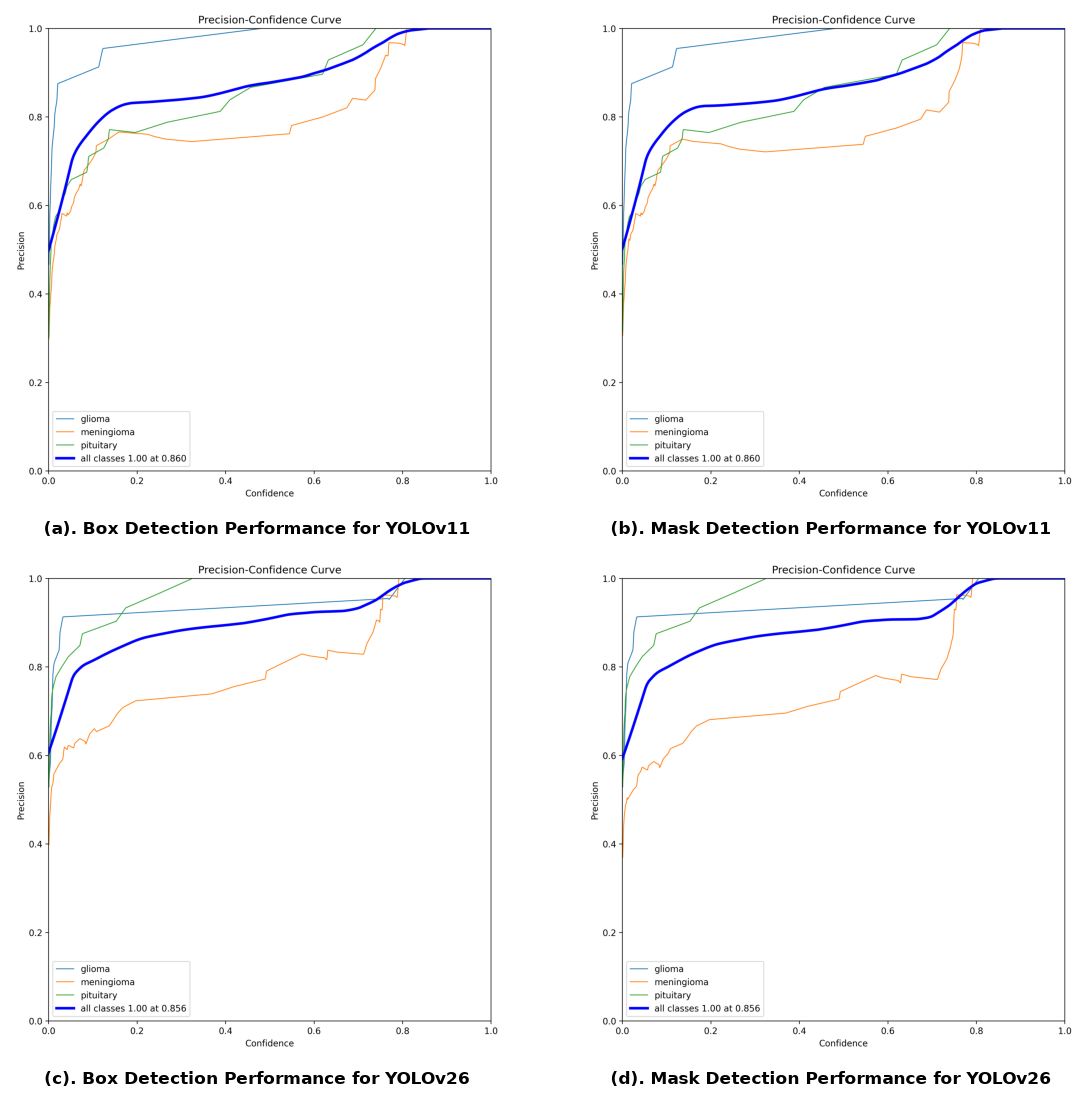

Saved: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures\Figure_10_Precision_Confidence_Curve.png


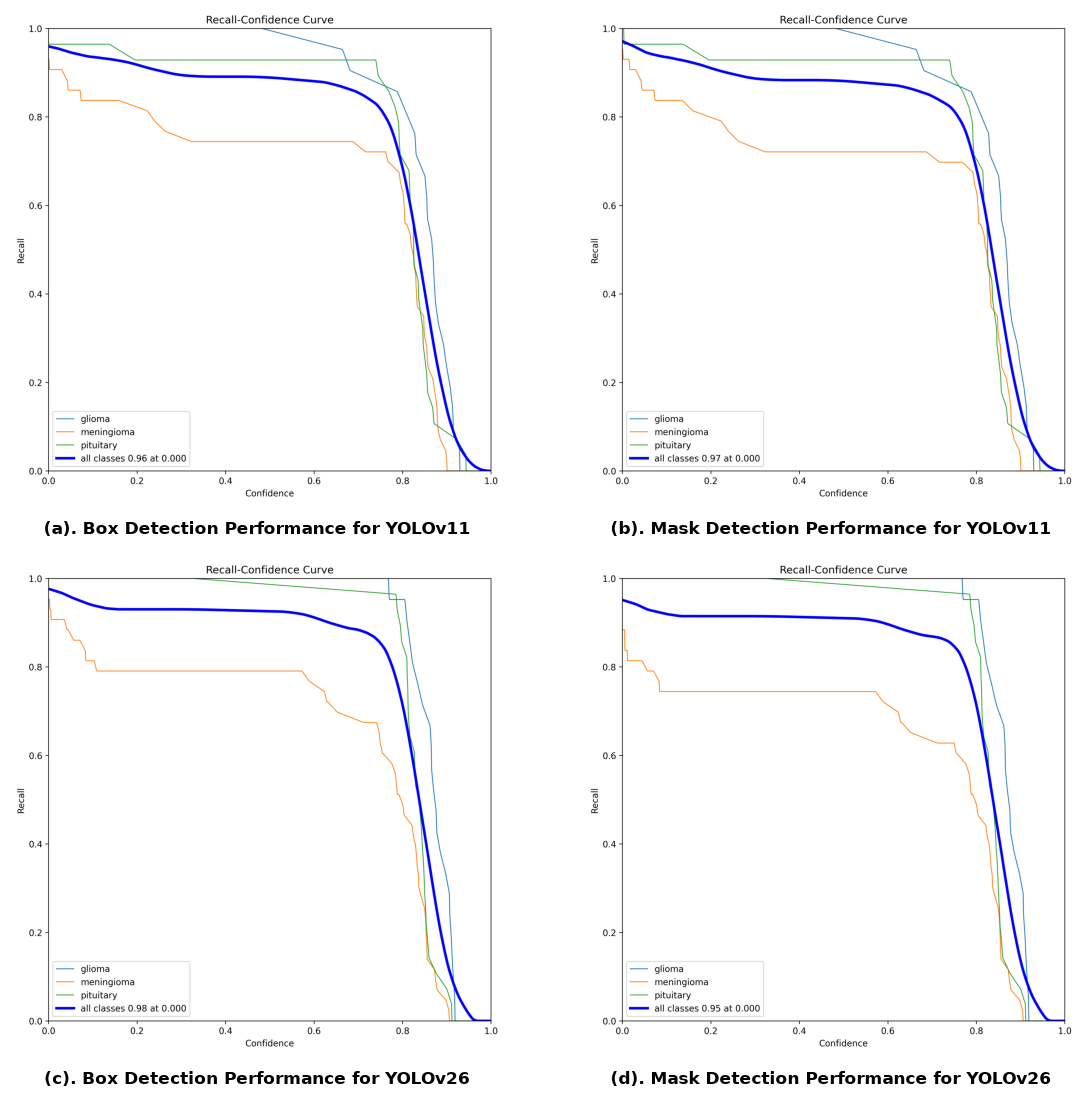

Saved: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures\Figure_11_Recall_Confidence_Curve.png


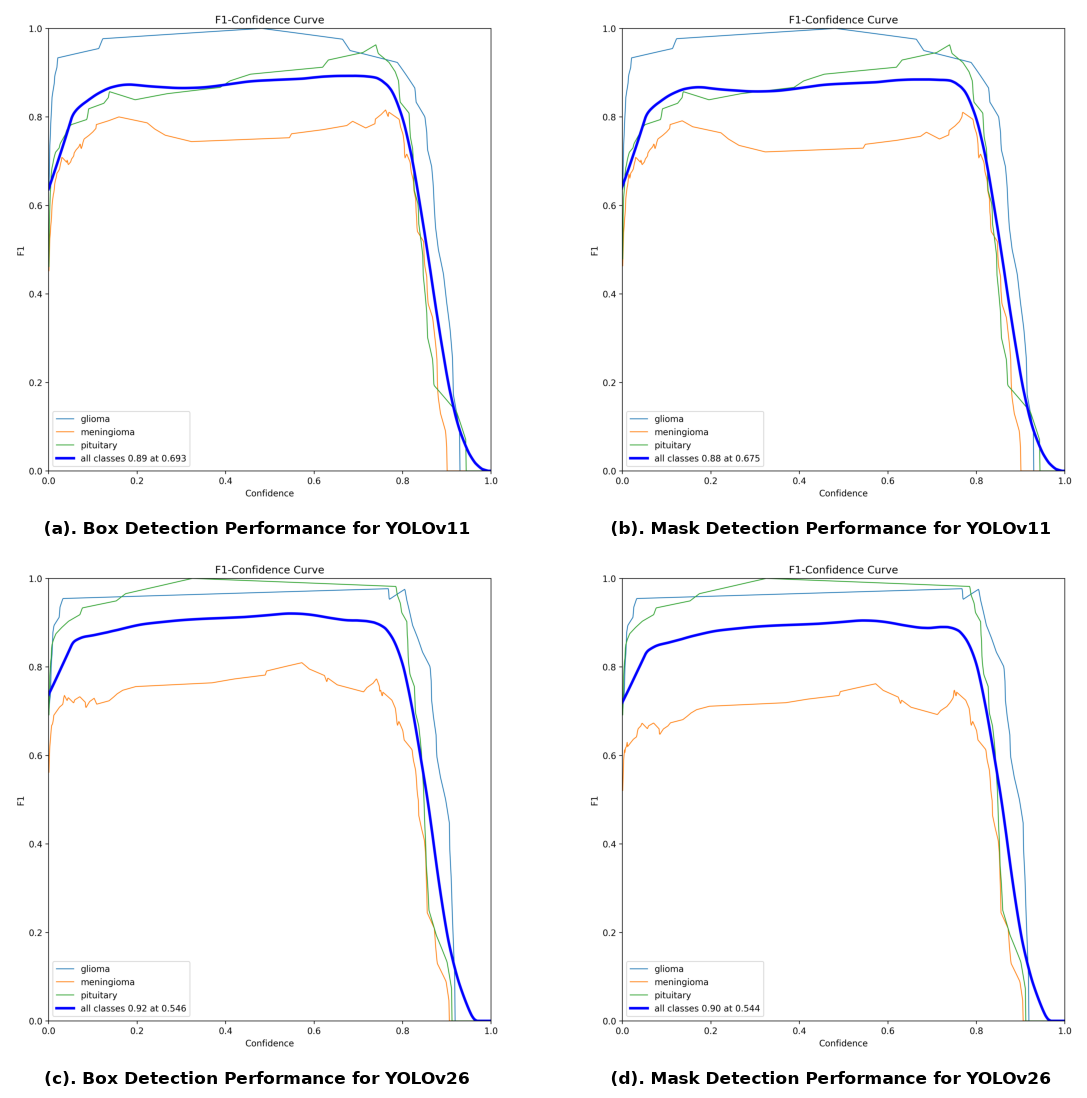

Saved: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures\Figure_12_F1_Confidence_Curve.png


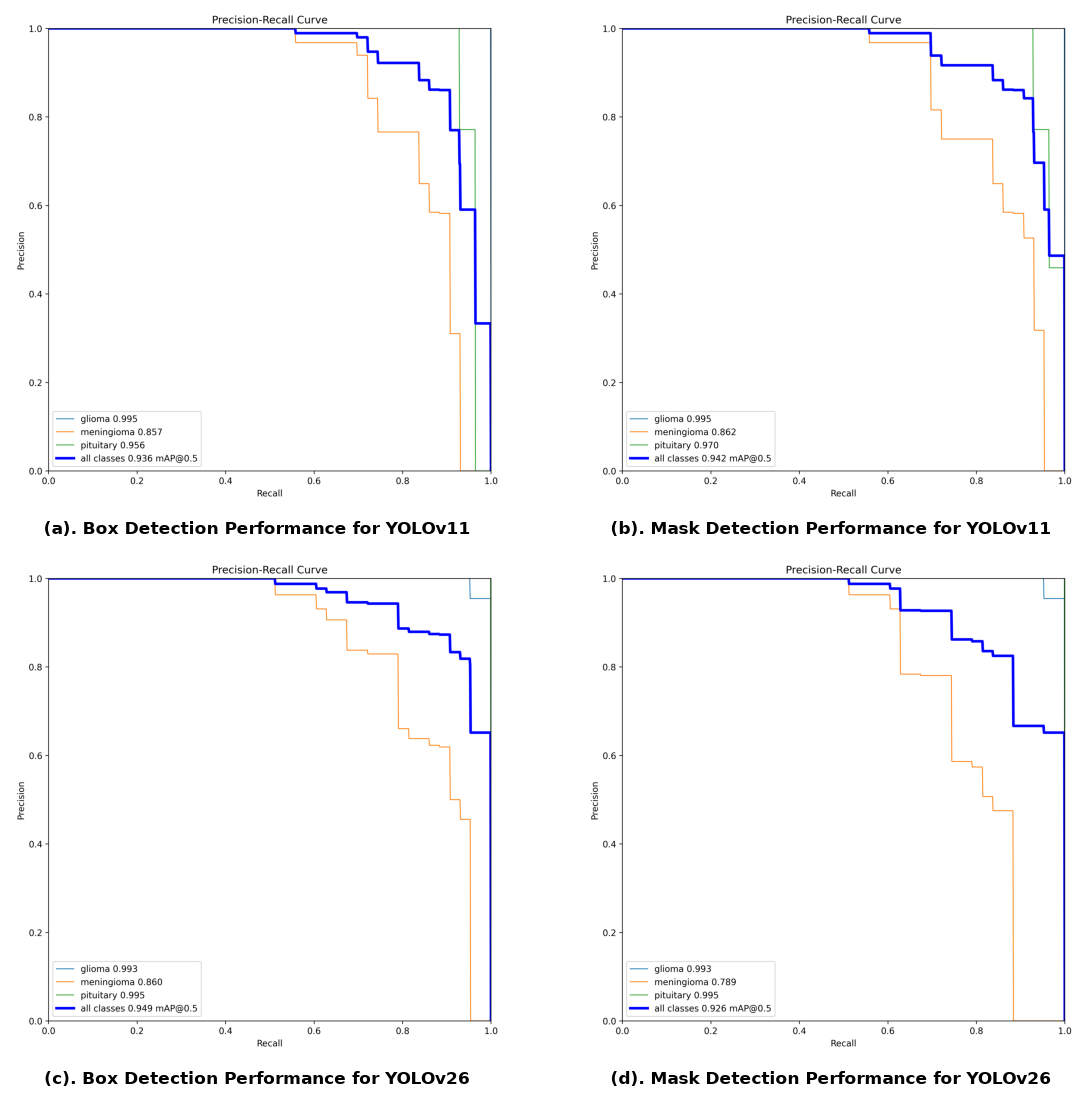

Saved: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures\Figure_13_Precision_Recall_Curve.png


In [6]:

saved_paths = []

for spec in CURVE_FIGURES:
    panels = [
        (YOLO11_DIR, spec["box_file"],  f"(a). Box Detection Performance for {MODEL_A_NAME}"),
        (YOLO11_DIR, spec["mask_file"], f"(b). Mask Detection Performance for {MODEL_A_NAME}"),
        (YOLO26_DIR, spec["box_file"],  f"(c). Box Detection Performance for {MODEL_B_NAME}"),
        (YOLO26_DIR, spec["mask_file"], f"(d). Mask Detection Performance for {MODEL_B_NAME}"),
    ]
    out_name = f"Figure_{spec['number']}_{spec['slug']}.png"
    path = build_grid_figure(panels, out_name, grid_shape=(2, 2), figsize=(12, 11))
    saved_paths.append(path)


## 7. Build Figure 14 (Confusion Matrix, 1×2 grid)

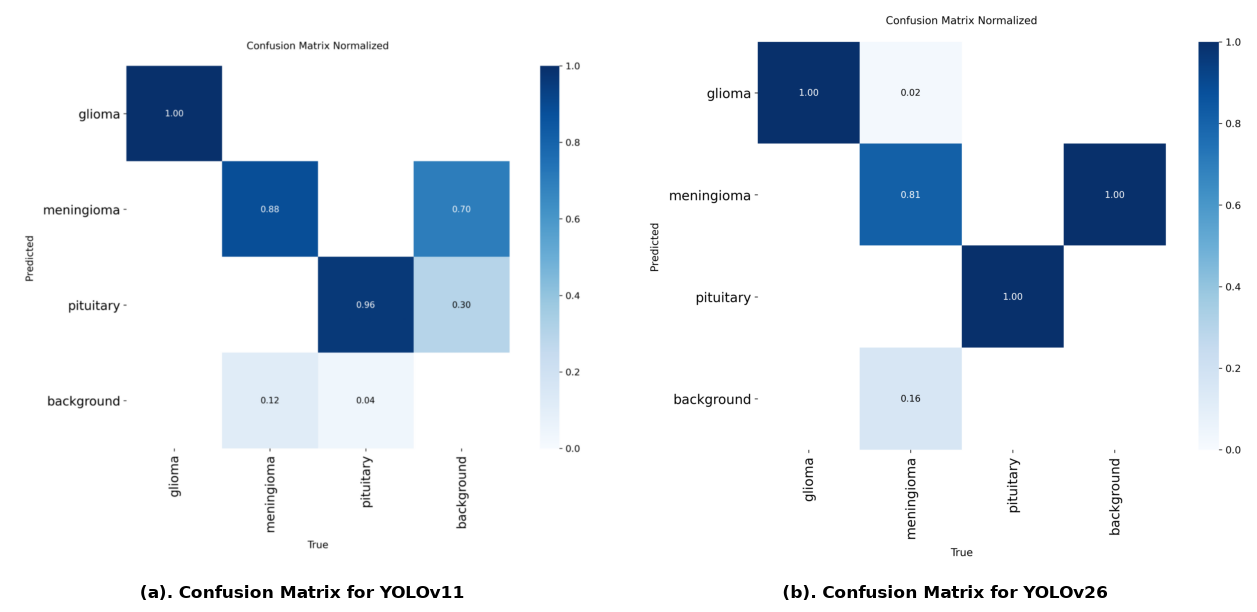

Saved: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures\Figure_14_Confusion_Matrix.png


In [7]:

cm_panels = [
    (YOLO11_DIR, "confusion_matrix_normalized.png", f"(a). Confusion Matrix for {MODEL_A_NAME}"),
    (YOLO26_DIR, "confusion_matrix_normalized.png", f"(b). Confusion Matrix for {MODEL_B_NAME}"),
]
cm_path = build_grid_figure(cm_panels, "Figure_14_Confusion_Matrix.png", grid_shape=(1, 2), figsize=(13, 6))
saved_paths.append(cm_path)


## 8. Summary

In [8]:

print("All figures saved to:", OUTPUT_DIR.resolve())
for p in saved_paths:
    print(" -", p.name)


All figures saved to: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures
 - Figure_10_Precision_Confidence_Curve.png
 - Figure_11_Recall_Confidence_Curve.png
 - Figure_12_F1_Confidence_Curve.png
 - Figure_13_Precision_Recall_Curve.png
 - Figure_14_Confusion_Matrix.png


### Notes
- Each panel has its own bold **(a)/(b)/(c)/(d)** sub-caption, matching the
  paper's style and alignment. No overall "Figure N. …" title is drawn on
  the image — add that text in Word underneath the image, as the rest of the
  paper does.
- To tweak spacing, adjust `figsize` (bigger relative to panel content = more
  whitespace) or `w_pad` / `h_pad` inside `fig.tight_layout(...)`.
- Re-run the whole notebook any time the underlying `val_run` folders are
  regenerated (e.g. after retraining) — all five figures will be rebuilt
  and overwritten with the latest results.


In [1]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager

# ============================================================
# EDIT THESE PATHS FOR YOUR MACHINE
# ============================================================
YOLO11_DIR = Path(r"C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv11x_Seg_Complete_Results\YOLOv11x-Seg\validation\val_run")
YOLO26_DIR = Path(r"C:\Users\miraj\Downloads\Brain_Tumor\Brain_Tumor_YOLOv26x_Seg_Complete_Results_best\YOLOv26x-Seg\validation\val_run")
OUTPUT_DIR = Path(r"C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_A_NAME = "YOLOv11"
MODEL_B_NAME = "YOLOv26"

# Layout settings — kept minimal so nothing extra is added
GAP = 20               # px gap between panels (horizontal & vertical)
CAPTION_HEIGHT = 55    # px reserved below each panel for its (a)/(b)/(c)/(d) caption
CAPTION_FONT_SIZE = 32
BG_COLOR = (255, 255, 255)

# Real bold TrueType font (borrowed from matplotlib's bundled fonts — crisp text, no extra deps)
FONT_PATH = font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold"))
FONT = ImageFont.truetype(FONT_PATH, CAPTION_FONT_SIZE)
# ============================================================


def load_image(base_dir, filename):
    """Load one validation JPG/PNG at full native resolution (no resampling)."""
    path = Path(base_dir) / filename
    if not path.exists():
        raise FileNotFoundError(f"Could not find:\n  {path}")
    return Image.open(path).convert("RGB")


def add_caption(img, text):
    """Return img with a bold caption centered directly beneath it."""
    w, h = img.size
    canvas = Image.new("RGB", (w, h + CAPTION_HEIGHT), BG_COLOR)
    canvas.paste(img, (0, 0))
    draw = ImageDraw.Draw(canvas)
    bbox = draw.textbbox((0, 0), text, font=FONT)
    text_w, text_h = bbox[2] - bbox[0], bbox[3] - bbox[1]
    x = (w - text_w) // 2
    y = h + (CAPTION_HEIGHT - text_h) // 2 - bbox[1]
    draw.text((x, y), text, fill=(0, 0, 0), font=FONT)
    return canvas


def build_grid_image(panels, out_filename, grid_shape=(2, 2)):
    """
    Compose panels into one high-resolution grid, pixel-exact (no matplotlib
    resampling/blur), with a caption under each panel and a fixed small gap
    between panels — nothing extra added.

    panels: list of (base_dir, filename, caption) in ROW-MAJOR reading order
            (top-left, top-right, bottom-left, bottom-right, ...)
    """
    rows, cols = grid_shape
    tiles = [add_caption(load_image(b, f), cap) for b, f, cap in panels]

    # Normalize all tiles to the same size so the grid lines up cleanly
    max_w = max(t.width for t in tiles)
    max_h = max(t.height for t in tiles)
    tiles = [t if t.size == (max_w, max_h) else t.resize((max_w, max_h), Image.LANCZOS) for t in tiles]

    canvas_w = cols * max_w + (cols - 1) * GAP
    canvas_h = rows * max_h + (rows - 1) * GAP
    canvas = Image.new("RGB", (canvas_w, canvas_h), BG_COLOR)

    for idx, tile in enumerate(tiles):
        r, c = divmod(idx, cols)
        canvas.paste(tile, (c * (max_w + GAP), r * (max_h + GAP)))

    out_path = OUTPUT_DIR / out_filename
    canvas.save(out_path, format="PNG", optimize=True)
    print(f"Saved: {out_path.resolve()}  ({canvas.width}x{canvas.height}px)")
    return out_path


# ---- Figure 15: Validation vs Prediction batches, YOLOv11 vs YOLOv26 ----
fig15_panels = [
    (YOLO11_DIR, "val_batch0_labels.jpg", f"(a). Validation Batch 0 for {MODEL_A_NAME}"),
    (YOLO26_DIR, "val_batch0_labels.jpg", f"(c). Validation Batch 0 for {MODEL_B_NAME}"),
    (YOLO11_DIR, "val_batch0_pred.jpg",   f"(b). Prediction Batch 0 for {MODEL_A_NAME}"),
    (YOLO26_DIR, "val_batch0_pred.jpg",   f"(d). Prediction Batch 0 for {MODEL_B_NAME}"),
]
build_grid_image(fig15_panels, "Figure_15_Validation_Prediction_Batches.png", grid_shape=(2, 2))

Saved: C:\Users\miraj\Downloads\Brain_Tumor\IEEE_Paper_Figures\Figure_15_Validation_Prediction_Batches.png  (2324x2434px)


WindowsPath('C:/Users/miraj/Downloads/Brain_Tumor/IEEE_Paper_Figures/Figure_15_Validation_Prediction_Batches.png')